## Análisis exploratorio de los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("../data/raw/billboard_hot_100_spotify_audio_features_enriched.csv")

df.head()

,song_id,performer,song,spotify_genre,spotify_track_id,spotify_track_preview_url,spotify_track_duration_ms,spotify_track_explicit,spotify_track_album,danceability,...,weeks_on_chart,first_week,last_week,chart_success_tier,hit_longevity_profile,acoustic_mood_cluster,musical_era,evidence_span,cot_rationale,confidence_score
0,Blinding LightsThe Weeknd,The Weeknd,Blinding Lights,"['canadian contemporary r&b', 'canadian pop', ...",0sf12qNH5qcw8qpgymFOqD,NaN,201573.0,False,Blinding Lights,0.513,...,76.0,2019-12-14,2021-05-29,historic_number_one,mega_marathon_hit,intense_aggressive_drive,digital_streaming_explosion,"The Weeknd - Blinding Lights: peak=1, weeks=76...",Psychoacoustic and commercial chart telemetry ...,0.966
1,Party Rock AnthemLMFAO Featuring Lauren Bennet...,LMFAO Featuring Lauren Bennett & GoonRock,Party Rock Anthem,"['dance pop', 'pop', 'pop rap']",0IkKz2J93C94Ei4BvDop7P,NaN,262173.0,False,Sorry For Party Rocking,0.750,...,68.0,2011-02-12,2012-07-21,historic_number_one,mega_marathon_hit,intense_aggressive_drive,digital_streaming_explosion,LMFAO Featuring Lauren Bennett & GoonRock - Pa...,Psychoacoustic and commercial chart telemetry ...,0.956
2,Rolling In The DeepAdele,Adele,Rolling In The Deep,"['british soul', 'pop', 'uk pop']",1CkvWZme3pRgbzaxZnTl5X,https://p.scdn.co/mp3-preview/8c174ce25d94b502...,228293.0,False,21,0.729,...,65.0,2010-12-25,2012-04-14,historic_number_one,mega_marathon_hit,balanced_acoustic_pop,digital_streaming_explosion,"Adele - Rolling In The Deep: peak=1, weeks=65,...",Psychoacoustic and commercial chart telemetry ...,0.959
3,CirclesPost Malone,Post Malone,Circles,"['dfw rap', 'melodic rap', 'rap']",21jGcNKet2qwijlDFuPiPb,NaN,215280.0,False,Hollywood's Bleeding,0.695,...,61.0,2019-09-14,2020-11-07,historic_number_one,mega_marathon_hit,balanced_acoustic_pop,digital_streaming_explosion,"Post Malone - Circles: peak=1, weeks=61, dance...",Psychoacoustic and commercial chart telemetry ...,0.965
4,Macarena (Bayside Boys Mix)Los Del Rio,Los Del Rio,Macarena (Bayside Boys Mix),"['deep norteno', 'duranguense', 'norteno', 'no...",NaN,NaN,NaN,NaN,NaN,NaN,...,60.0,1995-09-02,1997-02-08,historic_number_one,mega_marathon_hit,balanced_acoustic_pop,mtv_synth_pop_boom,Los Del Rio - Macarena (Bayside Boys Mix): pea...,Psychoacoustic and commercial chart telemetry ...,0.945


In [3]:
print(df.shape)

df.info()

(32503, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32503 entries, 0 to 32502
Data columns (total 33 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   song_id                    32503 non-null  object 
 1   performer                  32503 non-null  object 
 2   song                       32503 non-null  object 
 3   spotify_genre              30903 non-null  object 
 4   spotify_track_id           27397 non-null  object 
 5   spotify_track_preview_url  16763 non-null  object 
 6   spotify_track_duration_ms  27397 non-null  float64
 7   spotify_track_explicit     27397 non-null  object 
 8   spotify_track_album        27391 non-null  object 
 9   danceability               27334 non-null  float64
 10  energy                     27334 non-null  float64
 11  key                        27334 non-null  float64
 12  loudness                   27334 non-null  float64
 13  mode                       27334 n

In [4]:
df.columns[df.notna().all()].tolist()

['song_id',
 'performer',
 'song',
 'chart_success_tier',
 'hit_longevity_profile',
 'acoustic_mood_cluster',
 'musical_era',
 'evidence_span',
 'cot_rationale',
 'confidence_score']

## Filas duplicadas:
- Analizamos el número de canciones que estan repetidas, evitando así los duplicados.

In [5]:
repetidas = df["song_id"].duplicated().sum()

print("Registros con song_id repetido:", repetidas)

Registros con song_id repetido: 137


In [6]:
df = df.drop_duplicates(subset=["song_id"])

## Analizamos: 
- Las únicas columnas que no tienen valores nulos son: 
    - song_id
    - performer
    - song
    - chart_success_tier
    - hit_longevity_profile
    - acoustic_mood_cluster
    - musical_era
    - evidence_span
    - cot_rationale
    - confidence_score

- Seleccionamos nuestra y:
    - Crearemos una nueva columna que será "top30". Para ello usaremos "peak_position" y contendrá 1 si la canción llega al top 30 y 0 si no lo hace.

- Ahora seleccionaremos las columnas que consideramos necesarias para el análisis. 

In [7]:
df["top30"] = (
    df["peak_position"] <= 30
).astype(int)

## Limpieza de columnas:
- Estas son las columnas que hemos considerado innecesarias o problemáticas(variables a futuro):
    - song_id -> Es el id de la canción.
    - song -> Es el título de la canción.
    - spotify_track_id -> Es el id en spotify.
    - spotify_track_preview_url -> Es la url de la preview. 
    - spotify_track_album -> Es el álbum al que pertenece. 
    - liveness -> Es si ha sido grabada en directo o no.
    - spotify_track_popularity -> Cómo de popular ha sido cuando estaban en el top.
    - peak_position -> Es la posición que han tenido en el top. 
    - weeks_on_chart -> Son las semanas que han estado en el top. 
    - first_week -> Es la primera semana que ha entrado en el top. 
    - last_week -> Es la última semana que ha entrado en el top. 
    - chart_success_tier -> Es el nivel de éxito en las listas.
    - hit_longevity_profile -> Es el perfil de longevidad de éxito en el top.
    - valence -> Es un dato innecesario cuando se tiene acoustic_mood_cluster.
    - energy -> Es un dato innecesario cuando se tiene acoustic_mood_cluster.
    - acousticness -> Es un dato innecesario cuando se tiene acoustic_mood_cluster.
    - musical_era -> Es la era musical a la que pertenece. 
    - evidence_span -> Es el spam que han tenido. 
    - cot_rationale -> Es un indicativo para las ias. 
    - confidence_score -> Es la nota de confianza que han tenido por parte de las empresas. 




In [8]:
df = df.drop(columns=["song_id", "song", "spotify_track_id", "spotify_track_preview_url", "spotify_track_album", "liveness", "spotify_track_popularity", "peak_position", "weeks_on_chart", "first_week", "last_week", "chart_success_tier", "hit_longevity_profile", "valence", "energy", "acousticness", "musical_era", "evidence_span", "cot_rationale", "confidence_score"])

## Análisis de columnas en profundidad:
Analizamos las columnas "key" y "instrumentalness".

In [9]:
print(df['key'].value_counts().sort_index())

print("Valores ausentes:", df["key"].isna().sum())

key
0.0     3266
1.0     2389
2.0     2732
3.0     1044
4.0     2141
5.0     2430
6.0     1688
7.0     3099
8.0     1782
9.0     2676
10.0    2027
11.0    1931
Name: count, dtype: int64
Valores ausentes: 5161


In [10]:
print(df['instrumentalness'].value_counts().sort_index())

print("Valores ausentes:", df["instrumentalness"].isna().sum())
print("Valores ausentes:", df.isna().sum())

instrumentalness
0.000000    10295
0.000001        4
0.000001       17
0.000001       14
0.000001       15
            ...  
0.965000        2
0.966000        2
0.978000        1
0.981000        1
0.982000        2
Name: count, Length: 6227, dtype: int64
Valores ausentes: 5161
Valores ausentes: performer                       0
spotify_genre                1595
spotify_track_duration_ms    5098
spotify_track_explicit       5098
danceability                 5161
key                          5161
loudness                     5161
mode                         5161
speechiness                  5161
instrumentalness             5161
tempo                        5161
time_signature               5161
acoustic_mood_cluster           0
top30                           0
dtype: int64


## Analizando resultados:
- Las variables:
    - spotify_genre -> Al tener pocas filas con nulo optamos por borrarlas, ya que no se puede definir el género de la canción en base a otras canciones.          
    - spotify_track_duration_ms -> Optamos por usar la media, ya que la mayoría duran similar.
    - spotify_track_explicit -> Optamos por usar la moda, ya que la mayoria de canciones no son explícitas.     

Tienen valores nulos diferentes así que las analizaremos por separado.

- Las variables: 
    - danceability
    - key
    - loudness
    - mode     
    - speechiness                
    - instrumentalness          
    - tempo                     
    - time_signature  
     
Comparten el mísmo número de valores nulos, por lo que sospechamos que hay filas con los mísmos 8 atributos nulos. 

In [11]:
df.dropna(subset=['spotify_genre'], inplace=True)

 - Guardamos csv nuevo solamente quitando columnas y filas (sin dar valores a los nulos)

In [12]:
df.to_csv(
    "../data/raw/billboard_processed.csv",
    index=False,
    encoding="utf-8-sig"
)

In [13]:
variable_media = df["spotify_track_duration_ms"].mean()

variable_moda = df["spotify_track_explicit"].mode()[0]

df["spotify_track_duration_ms"] = df["spotify_track_duration_ms"].fillna(variable_media)

df["spotify_track_explicit"] = df["spotify_track_explicit"].fillna(variable_moda)

C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_27556\2547732098.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["spotify_track_explicit"] = df["spotify_track_explicit"].fillna(variable_moda)


In [14]:
print(df.shape)

cols_audio = [
    "danceability",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "instrumentalness",
    "tempo",
    "time_signature"
]

print("Nulos por atributo:")
print(df[cols_audio].isna().sum())

todos_vacios = df[cols_audio].isna().all(axis=1)
alguno_vacio = df[cols_audio].isna().any(axis=1)
todos_completos = df[cols_audio].notna().all(axis=1)

print("\n--- RESUMEN ---")
print("Filas totales:", len(df))
print("Filas con los 8 atributos vacíos:", todos_vacios.sum())
print("Filas con algunos atributos vacíos:", 
      (alguno_vacio & ~todos_vacios).sum())
print("Filas con los 8 atributos completos:", todos_completos.sum())


(30771, 14)
Nulos por atributo:
danceability        3709
key                 3709
loudness            3709
mode                3709
speechiness         3709
instrumentalness    3709
tempo               3709
time_signature      3709
dtype: int64

--- RESUMEN ---
Filas totales: 30771
Filas con los 8 atributos vacíos: 3709
Filas con algunos atributos vacíos: 0
Filas con los 8 atributos completos: 27062


In [15]:

cols_revision = [
    "performer",
    "spotify_track_duration_ms",
    "spotify_track_explicit",
    "spotify_genre",
    "danceability",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "instrumentalness",
    "tempo",
    "time_signature",
    "acoustic_mood_cluster",
]

muestra_20 = df.loc[todos_vacios, cols_revision].head(20)

display(muestra_20)


,performer,spotify_track_duration_ms,spotify_track_explicit,spotify_genre,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature,acoustic_mood_cluster
4,Los Del Rio,218888.37812,False,"['deep norteno', 'duranguense', 'norteno', 'no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop
16,Post Malone & Swae Lee,218888.37812,False,"['dfw rap', 'melodic rap', 'rap']",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop
61,Elton John,218888.37812,False,"['glam rock', 'mellow gold', 'piano rock', 'so...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop
78,Toni Braxton,218888.37812,False,"['dance pop', 'hip pop', 'neo soul', 'new jack...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop
98,Coolio Featuring L.V.,218888.37812,False,"['g funk', 'gangster rap', 'hip hop', 'rap', '...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop
104,Ke$ha,218888.37812,False,[],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop
128,Cardi B,218888.37812,False,"['pop', 'pop rap', 'rap']",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop
149,Boyz II Men,218888.37812,False,"['boy band', 'new jack swing', 'pop', 'quiet s...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop
184,Ini Kamoze,218888.37812,False,"['dub', 'lovers rock', 'reggae', 'reggae fusio...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop
195,Lisa Loeb & Nine Stories,218888.37812,False,"['lilith', 'new wave pop', 'pop rock', 'singer...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop


## Realizamos matríz de correlación: 
- Para poder decidir qué valores tendrán las variables nulas, realizamos la matríz de correlación para ver la correlación entre ellas. 
- No vemos relación evidente entre las variables

,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature
danceability,1.00,0.02,0.13,-0.15,0.21,-0.00,-0.12,0.20
key,0.02,1.00,0.01,-0.13,0.03,0.00,-0.01,0.01
loudness,0.13,0.01,1.00,-0.09,0.18,-0.13,0.09,0.11
mode,-0.15,-0.13,-0.09,1.00,-0.17,-0.01,0.01,-0.05
speechiness,0.21,0.03,0.18,-0.17,1.00,-0.04,0.08,0.07
instrumentalness,-0.00,0.00,-0.13,-0.01,-0.04,1.00,0.00,0.01
tempo,-0.12,-0.01,0.09,0.01,0.08,0.00,1.00,-0.01
time_signature,0.20,0.01,0.11,-0.05,0.07,0.01,-0.01,1.00


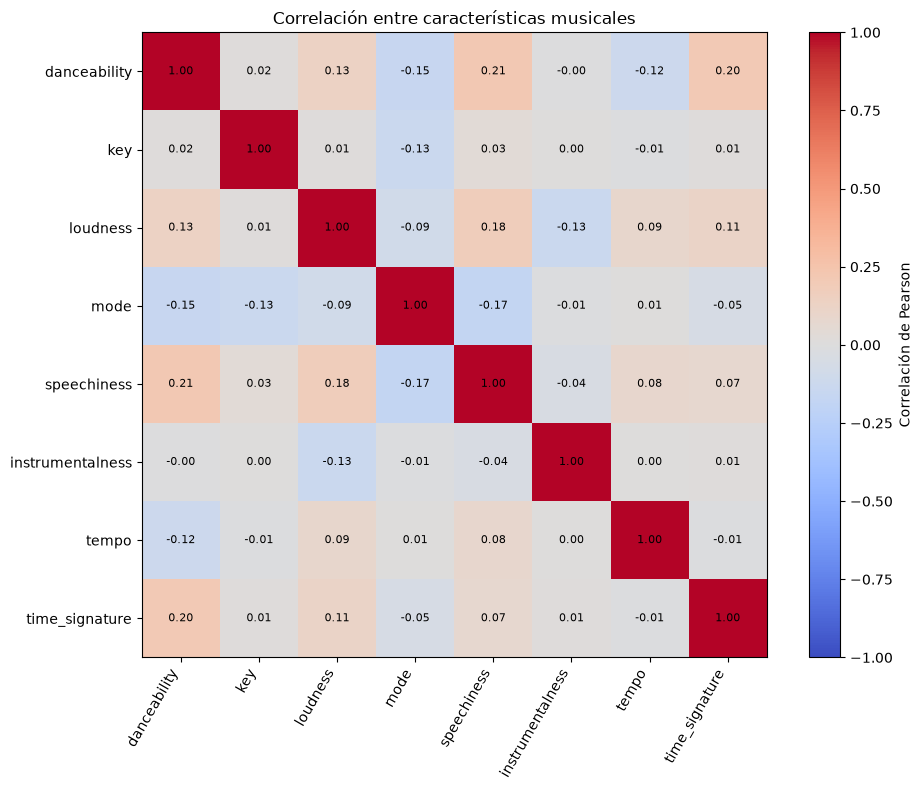

In [16]:

import pandas as pd
import matplotlib.pyplot as plt

audio_cols = [
    "danceability",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "instrumentalness",
    "tempo",
    "time_signature"
]

df[audio_cols] = df[audio_cols].apply(
    pd.to_numeric, errors="coerce"
)

corr = df[audio_cols].corr(method="pearson")

display(corr.round(2))

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")

ax.set_xticks(range(len(audio_cols)))
ax.set_xticklabels(audio_cols, rotation=60, ha="right")
ax.set_yticks(range(len(audio_cols)))
ax.set_yticklabels(audio_cols)

for i in range(len(audio_cols)):
    for j in range(len(audio_cols)):
        value = corr.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}",
                    ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Correlación entre características musicales")
plt.tight_layout()
plt.show()


## Matríz de correlación por cada cluster:
- Hemos analizado la correlación entre las variables por cada cluster y creemos que es la mejor opción para rellenar los nulos que rellenándolos de forma global, a pesar que las correlaciones siguen siendo bastante bajas.
    - "danceability" -> Media por cluster (Variable continua y relaciones insuficientes para predecirla con otras variables)
    - "key" -> Moda por cluster (Es una variable discreta que representa una tonalidad musical)
    - "loudness" -> Mediana por cluster (Es continua y puede presentar valores extremos)
    - "mode" -> Moda por cluster (Variable binaria (mayor o menor))
    - "speechiness" -> Media por cluster (Variable continua)
    - "instrumentalness" -> Media por cluster (Variable continua y correlaciones muy débiles)
    - "tempo" -> Media por cluster (Variable continua, sin relaciones suficientemente fuertes)
    - "time_signature" -> Moda por cluster (Variable discreta que representa el compás)

Número de clusters: 5
Clusters encontrados: ['balanced_acoustic_pop', 'chill_downtempo_groove', 'high_energy_euphoric', 'intense_aggressive_drive', 'moody_melancholic']

Cluster: balanced_acoustic_pop | Registros: 12526


,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature
danceability,1.00,0.02,0.10,-0.15,0.24,-0.01,-0.14,0.16
key,0.02,1.00,0.02,-0.13,0.03,0.02,-0.01,0.01
loudness,0.10,0.02,1.00,-0.07,0.16,-0.14,0.05,0.07
mode,-0.15,-0.13,-0.07,1.00,-0.18,-0.02,0.02,-0.05
speechiness,0.24,0.03,0.16,-0.18,1.00,-0.03,0.07,0.07
instrumentalness,-0.01,0.02,-0.14,-0.02,-0.03,1.00,0.02,0.02
tempo,-0.14,-0.01,0.05,0.02,0.07,0.02,1.00,-0.03
time_signature,0.16,0.01,0.07,-0.05,0.07,0.02,-0.03,1.00


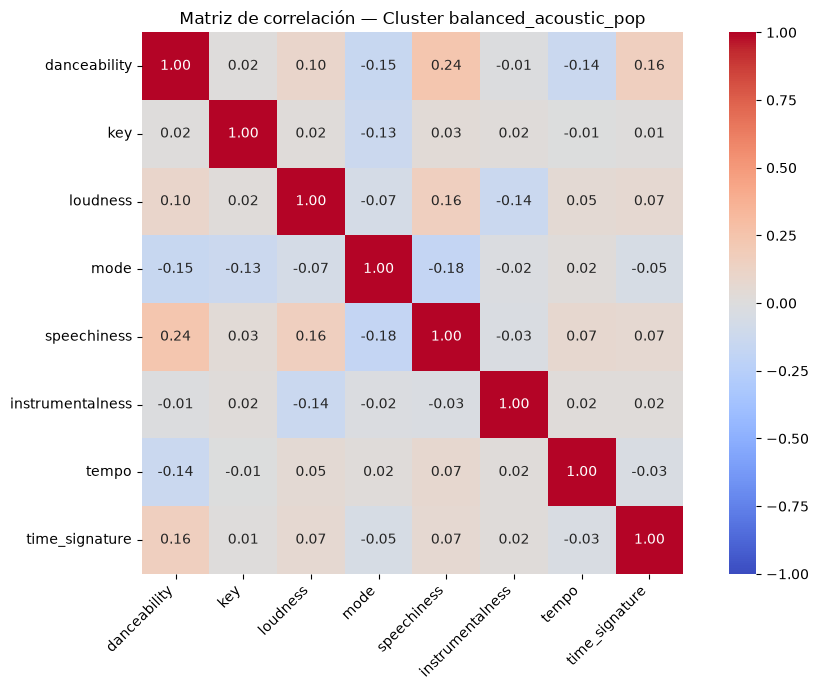


Cluster: chill_downtempo_groove | Registros: 6191


,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature
danceability,1.00,0.03,0.07,-0.14,0.20,0.03,-0.16,0.23
key,0.03,1.00,0.02,-0.12,0.03,0.01,0.01,-0.00
loudness,0.07,0.02,1.00,-0.10,0.21,-0.13,0.02,0.01
mode,-0.14,-0.12,-0.10,1.00,-0.17,-0.01,-0.01,-0.04
speechiness,0.20,0.03,0.21,-0.17,1.00,-0.04,0.08,0.07
instrumentalness,0.03,0.01,-0.13,-0.01,-0.04,1.00,0.01,0.02
tempo,-0.16,0.01,0.02,-0.01,0.08,0.01,1.00,-0.07
time_signature,0.23,-0.00,0.01,-0.04,0.07,0.02,-0.07,1.00


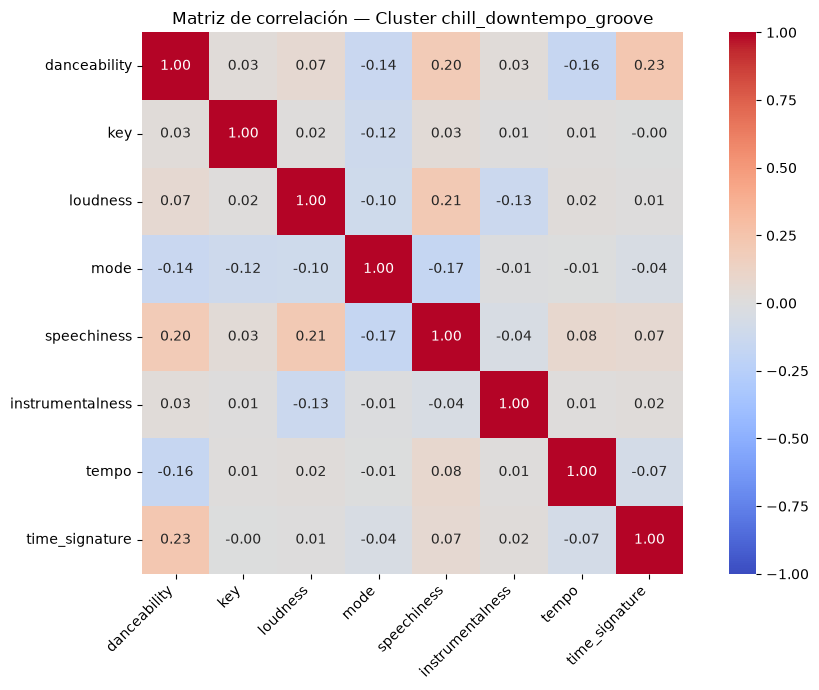


Cluster: high_energy_euphoric | Registros: 6453


,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature
danceability,1.00,0.02,0.03,-0.15,0.07,-0.01,-0.29,0.06
key,0.02,1.00,-0.00,-0.15,0.04,-0.01,-0.04,0.00
loudness,0.03,-0.00,1.00,-0.00,0.11,-0.17,-0.01,0.00
mode,-0.15,-0.15,-0.00,1.00,-0.14,0.00,0.07,-0.01
speechiness,0.07,0.04,0.11,-0.14,1.00,-0.07,0.02,-0.00
instrumentalness,-0.01,-0.01,-0.17,0.00,-0.07,1.00,0.00,-0.01
tempo,-0.29,-0.04,-0.01,0.07,0.02,0.00,1.00,-0.00
time_signature,0.06,0.00,0.00,-0.01,-0.00,-0.01,-0.00,1.00


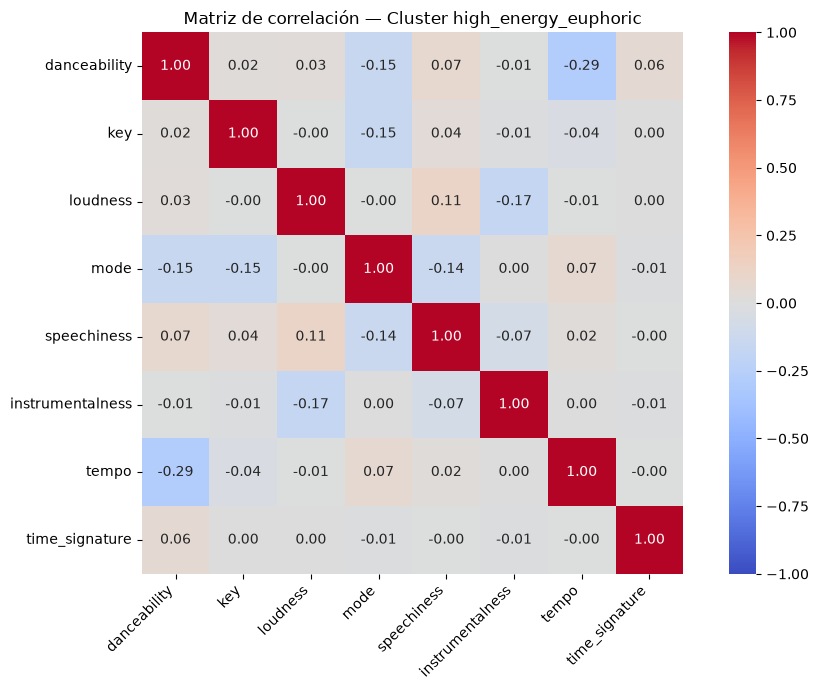


Cluster: intense_aggressive_drive | Registros: 2476


,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature
danceability,1.00,-0.00,-0.11,-0.09,0.18,-0.06,-0.19,0.06
key,-0.00,1.00,0.01,-0.12,0.03,0.02,-0.03,-0.00
loudness,-0.11,0.01,1.00,0.04,-0.13,-0.12,0.04,-0.00
mode,-0.09,-0.12,0.04,1.00,-0.15,-0.00,0.02,0.01
speechiness,0.18,0.03,-0.13,-0.15,1.00,-0.01,0.08,0.03
instrumentalness,-0.06,0.02,-0.12,-0.00,-0.01,1.00,0.03,-0.02
tempo,-0.19,-0.03,0.04,0.02,0.08,0.03,1.00,-0.04
time_signature,0.06,-0.00,-0.00,0.01,0.03,-0.02,-0.04,1.00


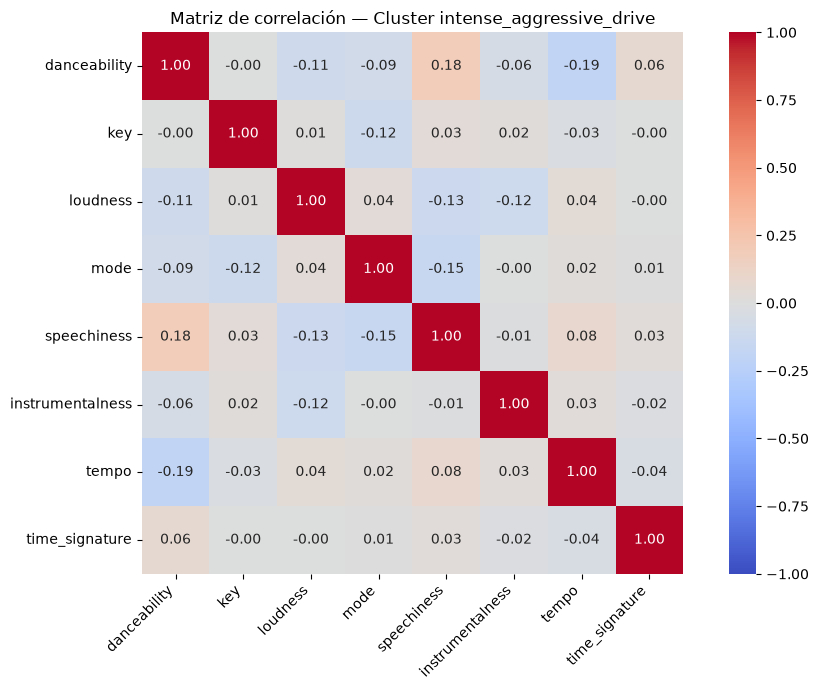


Cluster: moody_melancholic | Registros: 3125


,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature
danceability,1.00,-0.03,0.28,-0.18,0.41,-0.04,0.04,0.22
key,-0.03,1.00,-0.01,-0.07,0.01,-0.01,-0.03,0.01
loudness,0.28,-0.01,1.00,-0.09,0.24,-0.15,0.11,0.08
mode,-0.18,-0.07,-0.09,1.00,-0.21,-0.02,-0.05,-0.08
speechiness,0.41,0.01,0.24,-0.21,1.00,-0.02,0.13,0.11
instrumentalness,-0.04,-0.01,-0.15,-0.02,-0.02,1.00,-0.05,0.01
tempo,0.04,-0.03,0.11,-0.05,0.13,-0.05,1.00,-0.02
time_signature,0.22,0.01,0.08,-0.08,0.11,0.01,-0.02,1.00


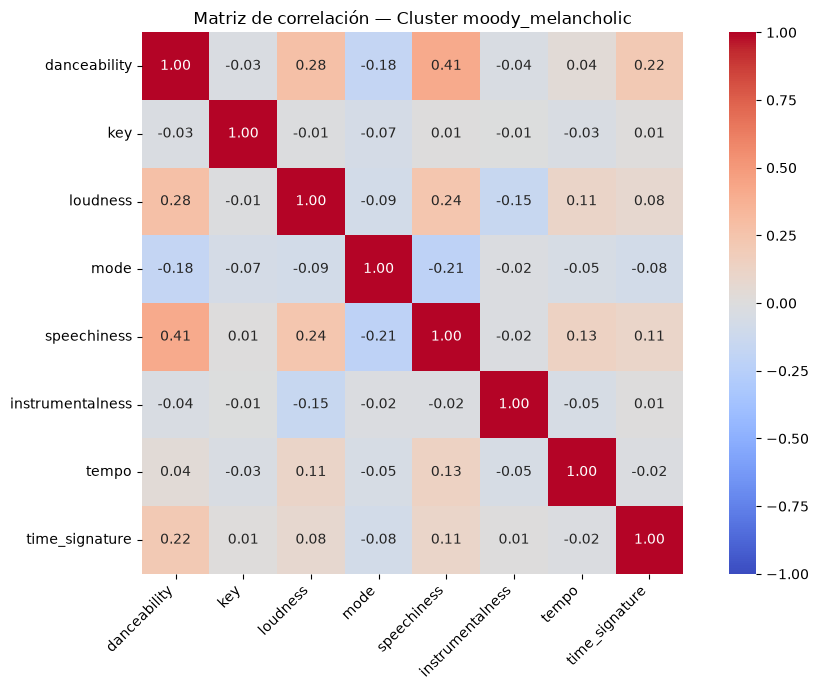

In [17]:
variables = [
    "danceability",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "instrumentalness",
    "tempo",
    "time_signature"
]

variables = [col for col in variables if col in df.columns]

clusters = sorted(df["acoustic_mood_cluster"].dropna().unique())

print(f"Número de clusters: {len(clusters)}")
print(f"Clusters encontrados: {clusters}")

matrices_correlacion = {}

for cluster in clusters:
    df_cluster = df.loc[
        df["acoustic_mood_cluster"] == cluster,
        variables
    ]

    matriz = df_cluster.corr(method="pearson")
    matrices_correlacion[cluster] = matriz

    print(f"\nCluster: {cluster} | Registros: {len(df_cluster)}")
    display(matriz.round(2))

    plt.figure(figsize=(10, 7))
    sns.heatmap(
        matriz,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True
    )

    plt.title(f"Matriz de correlación — Cluster {cluster}")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


In [18]:
variables_media = [
    "danceability",
    "speechiness",
    "instrumentalness",
    "tempo"
]

variables_mediana = [
    "loudness"
]

variables_moda = [
    "key",
    "mode",
    "time_signature"
]

cluster_col = "acoustic_mood_cluster"

df_imputado = df.copy()

for col in variables_media:
    valor_cluster = df_imputado.groupby(cluster_col)[col].transform("mean")
    df_imputado[col] = df_imputado[col].fillna(valor_cluster)
    df_imputado[col] = df_imputado[col].fillna(df_imputado[col].mean())

for col in variables_mediana:
    valor_cluster = df_imputado.groupby(cluster_col)[col].transform("median")
    df_imputado[col] = df_imputado[col].fillna(valor_cluster)
    df_imputado[col] = df_imputado[col].fillna(df_imputado[col].median())

for col in variables_moda:
    valor_cluster = df_imputado.groupby(cluster_col)[col].transform(
        lambda x: x.mode().iloc[0] if not x.mode().empty else float("nan")
    )

    df_imputado[col] = df_imputado[col].fillna(valor_cluster)

    moda_global = df_imputado[col].mode()
    if not moda_global.empty:
        df_imputado[col] = df_imputado[col].fillna(moda_global.iloc[0])

columnas = variables_media + variables_mediana + variables_moda

print("Nulos antes:")
print(df[columnas].isna().sum())

print("\nNulos después:")
print(df_imputado[columnas].isna().sum())


Nulos antes:
danceability        3709
speechiness         3709
instrumentalness    3709
tempo               3709
loudness            3709
key                 3709
mode                3709
time_signature      3709
dtype: int64

Nulos después:
danceability        0
speechiness         0
instrumentalness    0
tempo               0
loudness            0
key                 0
mode                0
time_signature      0
dtype: int64


## Comparar relleno de variables de forma global o por cluster:
- Para comparar las variables continuas utilizaremos MAE y para las variables discretas utilizaremos el accuracy.

In [19]:
rng = np.random.default_rng(42)

porcentaje_ocultacion = 0.20

resultados = []

for col in variables_media + variables_mediana + variables_moda:

    indices_validos = df.index[df[col].notna()]

    n_ocultar = int(len(indices_validos) * porcentaje_ocultacion)

    indices_ocultos = rng.choice(
        indices_validos,
        size=n_ocultar,
        replace=False
    )

    valores_reales = df.loc[indices_ocultos, col]

    datos_entrenamiento = df.drop(index=indices_ocultos)

    if col in variables_media:
        valor_global = datos_entrenamiento[col].mean()
    elif col in variables_mediana:
        valor_global = datos_entrenamiento[col].median()
    else:
        moda_global = datos_entrenamiento[col].mode()
        valor_global = moda_global.iloc[0] if not moda_global.empty else np.nan

    if col in variables_media:
        estadisticos_cluster = datos_entrenamiento.groupby(cluster_col)[col].mean()
    elif col in variables_mediana:
        estadisticos_cluster = datos_entrenamiento.groupby(cluster_col)[col].median()
    else:
        estadisticos_cluster = datos_entrenamiento.groupby(cluster_col)[col].agg(
            lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
        )

    pred_global = pd.Series(
        valor_global,
        index=indices_ocultos
    )

    clusters_ocultos = df.loc[indices_ocultos, cluster_col]

    pred_cluster = clusters_ocultos.map(estadisticos_cluster)

    pred_cluster = pred_cluster.fillna(valor_global)

    if col in variables_media + variables_mediana:

        mae_global = np.mean(np.abs(valores_reales - pred_global))
        mae_cluster = np.mean(np.abs(valores_reales - pred_cluster))

        resultados.append({
            "variable": col,
            "metrica": "MAE (menor es mejor)",
            "global": mae_global,
            "por_cluster": mae_cluster
        })

    else:

        accuracy_global = np.mean(valores_reales == pred_global)
        accuracy_cluster = np.mean(valores_reales == pred_cluster)

        resultados.append({
            "variable": col,
            "metrica": "Accuracy (mayor es mejor)",
            "global": accuracy_global,
            "por_cluster": accuracy_cluster
        })

resultados_df = pd.DataFrame(resultados)

display(
    resultados_df.round(4)
)

,variable,metrica,global,por_cluster
0,danceability,MAE (menor es mejor),0.1249,0.1189
1,speechiness,MAE (menor es mejor),0.0709,0.0694
2,instrumentalness,MAE (menor es mejor),0.0537,0.0538
3,tempo,MAE (menor es mejor),22.8530,22.6877
4,loudness,MAE (menor es mejor),2.8387,2.3713
5,key,Accuracy (mayor es mejor),0.1240,0.1199
6,mode,Accuracy (mayor es mejor),0.7005,0.7005
7,time_signature,Accuracy (mayor es mejor),0.9279,0.9279


## Analizamos nuestras variables y las canciones que tienen 

In [20]:
print(df.columns.tolist())

['performer', 'spotify_genre', 'spotify_track_duration_ms', 'spotify_track_explicit', 'danceability', 'key', 'loudness', 'mode', 'speechiness', 'instrumentalness', 'tempo', 'time_signature', 'acoustic_mood_cluster', 'top30']


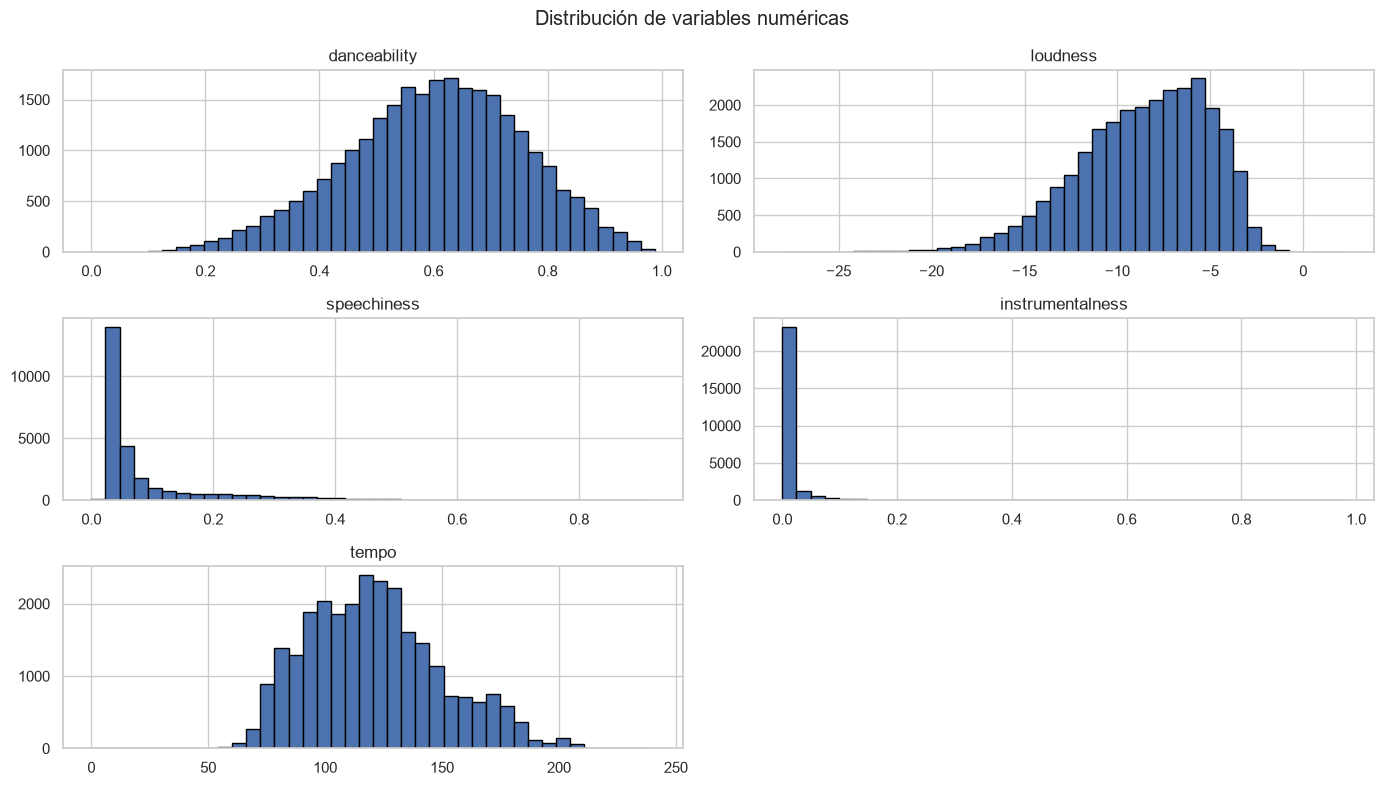

C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_27556\2469897992.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


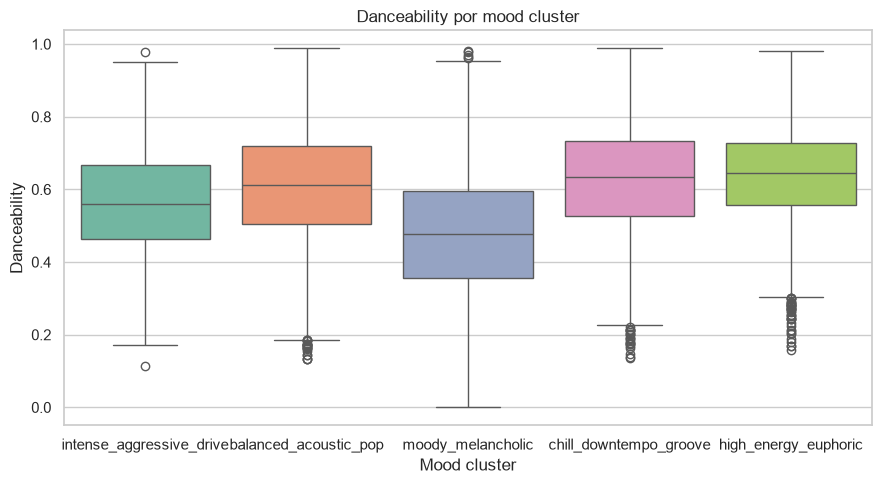

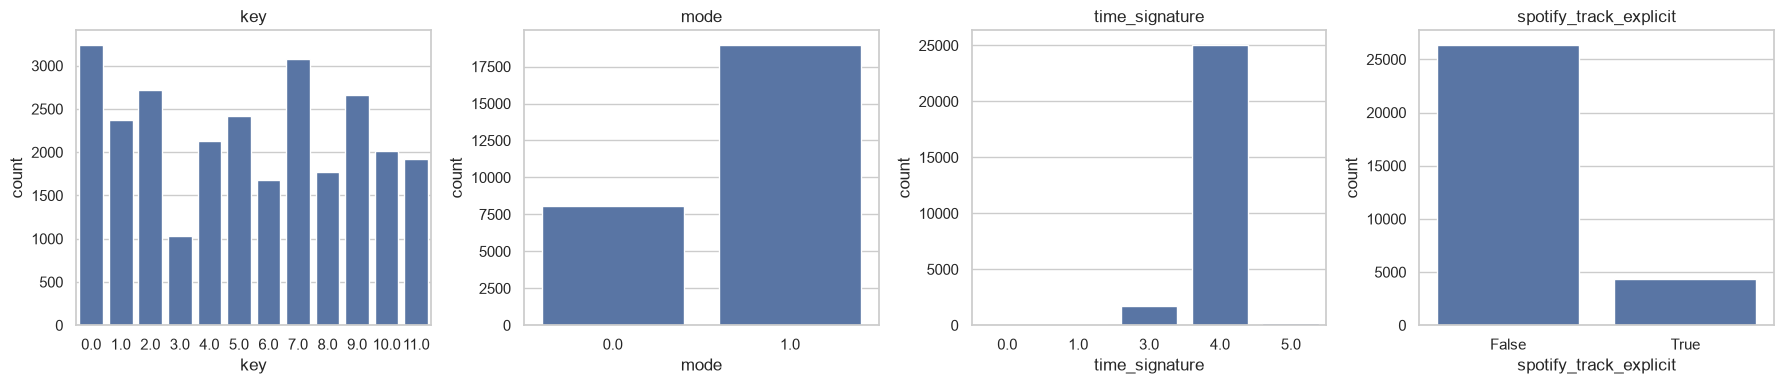

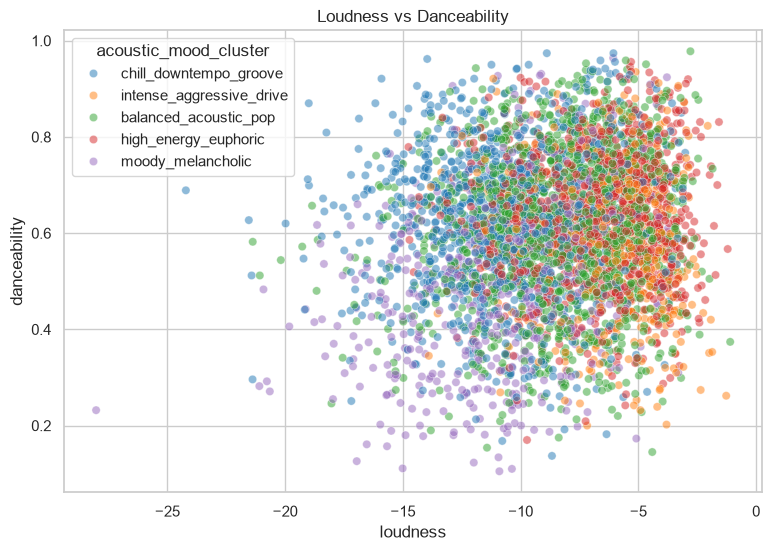

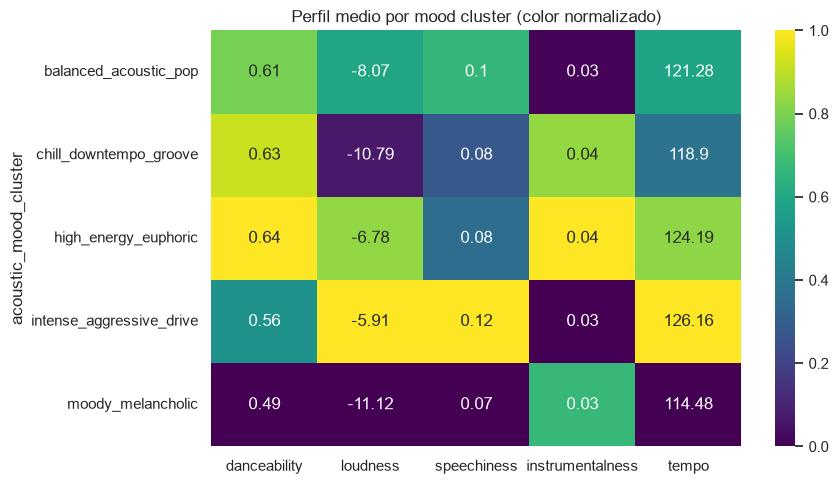

In [24]:

sns.set_theme(style='whitegrid')

# Crear duración en minutos
df['duration_min'] = df['spotify_track_duration_ms'] / 60000

# 1. Histogramas de todas las numéricas
num_plot = [ 'danceability', 'loudness', 'speechiness', 'instrumentalness', 'tempo']

df[num_plot].hist(bins=40, figsize=(14, 8), edgecolor='black')
plt.suptitle('Distribución de variables numéricas')
plt.tight_layout()
plt.show()

# Boxplot de danceability por mood cluster
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='acoustic_mood_cluster',
    y='danceability',
    palette='Set2'
)

plt.title('Danceability por mood cluster')
plt.xlabel('Mood cluster')
plt.ylabel('Danceability')
plt.tight_layout()
plt.show()

# 5. Countplots de variables categóricas
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, col in zip(axes, ['key', 'mode', 'time_signature', 'spotify_track_explicit']):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

# 7. Scatter: loudness vs danceability coloreado por mood
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df.sample(min(5000, len(df))),
    x='loudness',
    y='danceability',
    hue='acoustic_mood_cluster',
    alpha=0.5,
    palette='tab10'
)

plt.title('Loudness vs Danceability')
plt.show()


# 9. Heatmap de medias por mood cluster
perfil = df.groupby('acoustic_mood_cluster')[num_plot].mean()

perfil_norm = (perfil - perfil.min()) / (perfil.max() - perfil.min())

plt.figure(figsize=(9, 5))
sns.heatmap(
    perfil_norm,
    annot=perfil.round(2),
    fmt='',
    cmap='viridis'
)

plt.title('Perfil medio por mood cluster (color normalizado)')
plt.tight_layout()
plt.show()


### Evaluación del método de imputación de valores ausentes

Para seleccionar el método de imputación más adecuado, se realizó un experimento comparativo entre la imputación global y la imputación basada en la variable "acoustic_mood_cluster".

El experimento consistió en ocultar aleatoriamente el 20 % de los valores originalmente disponibles de cada variable y comparar los valores imputados con sus valores reales. Para las variables continuas se utilizó el error absoluto medio (MAE), mientras que para las variables discretas se empleó la exactitud (accuracy).

Los resultados mostraron que la imputación por cluster obtuvo mejores resultados en cinco de las ocho variables evaluadas. Las mejoras más destacadas se observaron en "loudness" (reducción del MAE del 16,55 %), "speechiness" (5,64 %) y "danceability" (5,10 %). En "instrumentalness" y "tempo" las diferencias fueron muy pequeñas, mientras que "mode" y "time_signature" presentaron resultados idénticos con ambos métodos.

A partir de estos resultados, se decidió utilizar la imputación por cluster como estrategia general, dado que ofrece mejoras en varias variables y no presenta un empeoramiento en las restantes. Esta decisión permite aprovechar las diferencias entre los perfiles acústicos de las canciones al estimar los valores ausentes.